### Deep Agents overview



Build agents that can plan, use subagents, and leverage file systems for complex tasks

deepagents is a standalone library for building agents that can tackle complex, multi-step tasks. Built on LangGraph and inspired by applications like Claude Code, Deep Research, and Manus, deep agents come with planning capabilities, file systems for context management, and the ability to spawn subagents.


### When to use deep agents
Use deep agents when you need agents that can:

- Handle complex, multi-step tasks that require planning and decomposition
- Manage large amounts of context through file system tools
- Delegate work to specialized subagents for context isolation
- Persist memory across conversations and threads

In [1]:
### Basic deep agent

import os
from dotenv import load_dotenv
load_dotenv()
os.environ["ANTHROPIC_API_KEY"]=os.getenv("ANTHROPIC_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [2]:
from typing import Literal

In [3]:
### Tools- Internet search
from tavily import TavilyClient
from typing import Literal

tavily_client=TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

def web_search(query:str,max_results:int=5,
topic: Literal["general","sports","news","finance"]="general",
include_raw_content:bool=False):
    """Run a web search"""
    return tavily_client.search(query,
    max_results=max_results,include_raw_content=include_raw_content,topic=topic)



In [16]:
from langchain.chat_models import init_chat_model

model=init_chat_model("anthropic:claude-sonnet-5-5")
model

ChatAnthropic(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-anthropic': '1.7.12'}}, profile={'name': 'Claude Sonnet 5.5', 'release_date': '2026-09-28', 'last_updated': '2026-09-28', 'open_weights': False, 'max_input_tokens': 1000000, 'max_output_tokens': 128000, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': False, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_call_streaming': True, 'tool_choice': False, 'reasoning_effort_levels': ['low', 'medium', 'high', 'xhigh', 'max'], 'reasoning_effort_default': 'high', 'mid_conversation_system_messages': True, 'mid_conversation_tools': True}, model='claude-sonnet-5-5', max_tokens=128000, anthropic_api_url='

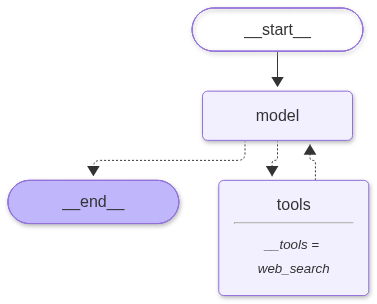

In [17]:
## Basic Agent
from langchain.agents import create_agent


simple_agent=create_agent(
    model=model,
    tools=[web_search]
)
simple_agent

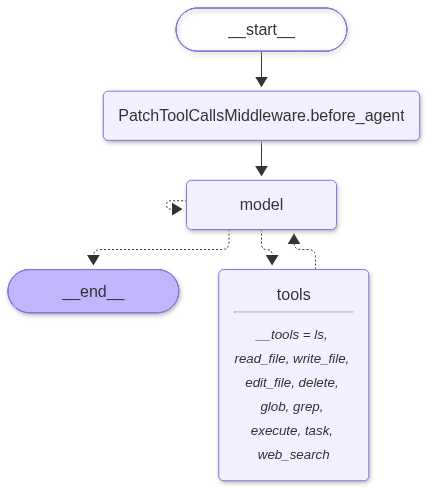

In [18]:
### Create a deep agent
## Prompt

## agent

from deepagents import create_deep_agent

deepagent=create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher"
)
deepagent

In [19]:
result = deepagent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='c980a533-0200-4874-97d2-ed787552acac'),
  AIMessage(content=[{'id': 'toolu_01GDjXVNehWnTaoKrvP9k8tK', 'caller': {'type': 'direct'}, 'input': {'query': 'deepagents LangChain "deep agents" what is', 'max_results': 5}, 'name': 'web_search', 'type': 'tool_use', 'toolset_name': None}, {'id': 'toolu_01KuSXViUroTdBEoUbgdUHsr', 'caller': {'type': 'direct'}, 'input': {'query': 'DeepAgent reasoning agent with scalable toolsets paper', 'max_results': 5}, 'name': 'web_search', 'type': 'tool_use', 'toolset_name': None}], additional_kwargs={}, response_metadata={'id': 'msg_011ChLbXMbRXta4sGJHNoi3S', 'container': None, 'diagnostics': None, 'model': 'claude-sonnet-5-5', 'stop_details': None, 'stop_reason': 'tool_use', 'stop_sequence': None, 'usage': {'cache_creation': {'ephemeral_1h_input_tokens': 0, 'ephemeral_5m_input_tokens': 3671}, 'cache_creation_input_tokens': 3671, 'cache_read_input_tokens':

In [20]:
result['messages'][-1].text

'"DeepAgent" can mean two different things. You may mean either one.\n\n## 1. Deep Agents (LangChain\'s `deepagents`)\nThis is the more common meaning. Deep Agents is an open-source **agent harness** from LangChain. A harness is an opinionated agent setup that runs out of the box. You can extend, override, or replace any piece of it. It\'s built for long-running, multi-step work such as research and coding. It includes:\n- **Planning tools:** the agent breaks a goal into steps, tracks progress, and adapts as it learns.\n- **Subagents:** the agent can delegate independent subtasks in parallel, and each subagent has its own isolated context.\n- **A virtual filesystem:** it stores context, skills, and long-term memory, and it persists knowledge across sessions.\n- **Context management:** this helps the agent keep going over long runs, for example through context compression.\n- **Model flexibility and oversight:** it works with any model provider, supports human-in-the-loop approval, and 

In [21]:
result['files']

{}